In [1]:

from google.colab import files

uploaded = files.upload()


Saving SWYNEX_Titanic_Cleaned.csv to SWYNEX_Titanic_Cleaned.csv


# SWYNEX Final Data Science Project – Titanic Survival Prediction

## 1. Problem Statement

The objective of this project is to analyze the Titanic passenger dataset and build a machine learning model to predict whether a passenger survived.

The project combines data preparation, exploratory data analysis (EDA), model training, evaluation, and conclusions into one end-to-end data science case study.

## 2. Project Objectives

- Clean and prepare the Titanic dataset.
- Explore passenger data using statistics and visualizations.
- Identify factors associated with passenger survival.
- Build a baseline machine learning model.
- Evaluate the model using suitable performance metrics.
- Discuss the limitations and possible improvements.

## 3. Tools and Technologies

- Python
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

## 4. Dataset Overview

The Titanic dataset contains passenger information such as age, sex, passenger class, fare, family information, embarkation port, and survival status.

The cleaned dataset contains 891 rows and 11 columns.

The target variable is `Survived`:
- 0 = Did not survive
- 1 = Survived

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("SWYNEX_Titanic_Cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df.head()


Dataset loaded successfully!
Dataset shape: (891, 11)

Missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Duplicate rows: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


Descriptive Statistics


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


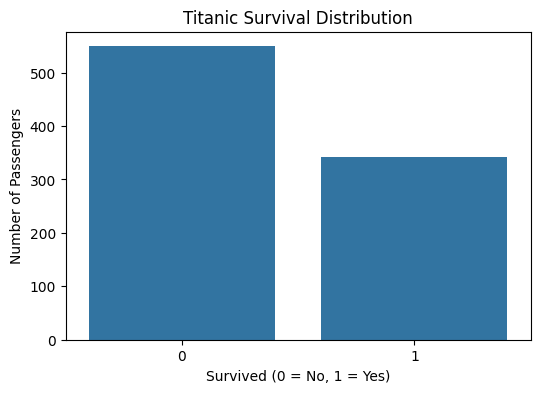

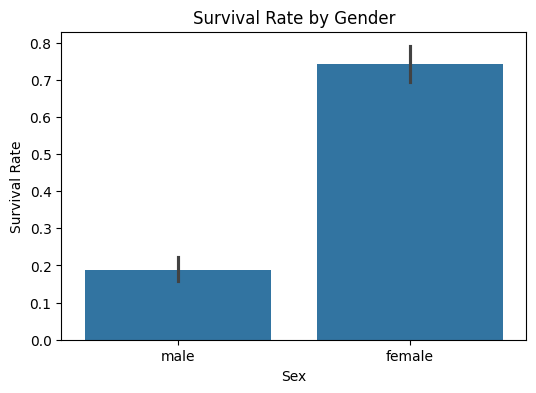

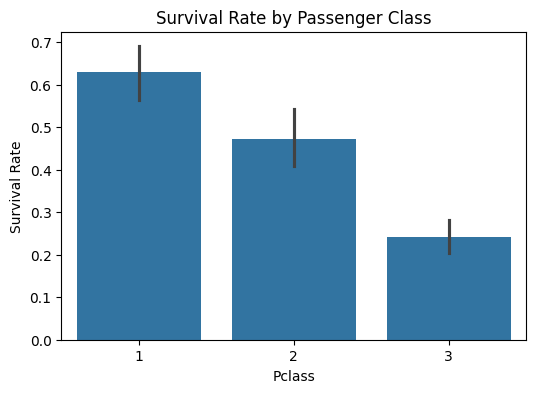

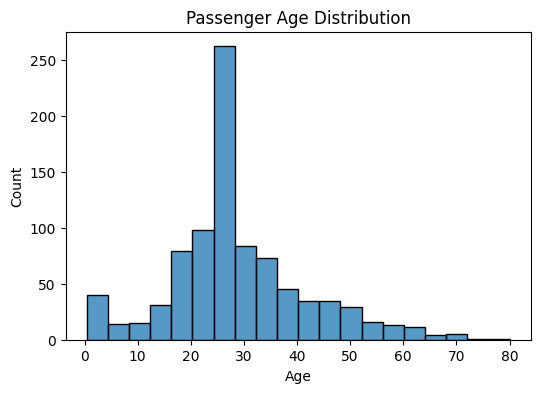

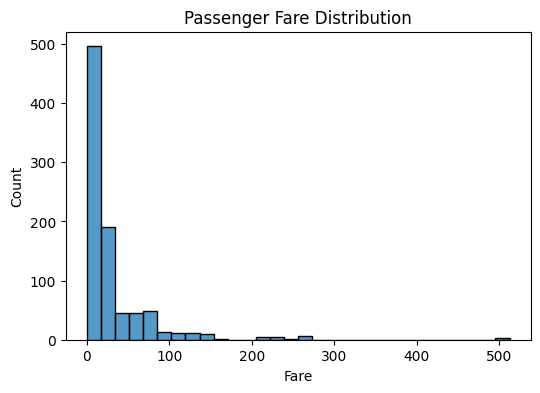

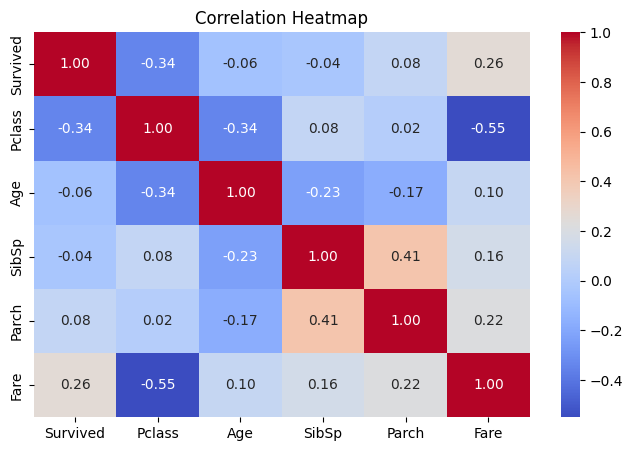

In [3]:

# 1. Descriptive Statistics
print("Descriptive Statistics")
display(df.describe())

# 2. Survival Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Survived")
plt.title("Titanic Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

# 3. Survival Rate by Gender
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Sex", y="Survived")
plt.title("Survival Rate by Gender")
plt.ylabel("Survival Rate")
plt.show()

# 4. Survival Rate by Passenger Class
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Pclass", y="Survived")
plt.title("Survival Rate by Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

# 5. Age Distribution
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="Age", bins=20)
plt.title("Passenger Age Distribution")
plt.show()

# 6. Fare Distribution
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="Fare", bins=30)
plt.title("Passenger Fare Distribution")
plt.show()

# 7. Correlation Heatmap
plt.figure(figsize=(8, 5))
corr = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


In [4]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Select features and target
X = df.drop(columns=["Survived", "PassengerId", "Name", "Ticket"])
y = df["Survived"]

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns

# Preprocessing pipeline
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

# Create Logistic Regression model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train the model
model.fit(X_train, y_train)

# Predict survival
y_pred = model.predict(X_test)

# Evaluate model
print("Model: Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model: Logistic Regression
Accuracy: 0.8045

Confusion Matrix:
[[98 12]
 [23 46]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



## 5. Key Findings from EDA

1. **Overall Survival:** Approximately 38.4% of passengers survived.
2. **Gender:** Female passengers had a substantially higher survival rate than male passengers.
3. **Passenger Class:** First-class passengers had a higher survival rate than third-class passengers.
4. **Age:** The average passenger age was approximately 29.4 years.
5. **Fare:** Most passengers paid relatively low fares, while a small number paid very high fares.
6. **Feature Relationships:** Correlation analysis helped identify relationships among numerical variables that may be useful for modeling.

## 6. Model Evaluation

A Logistic Regression classifier was trained to predict passenger survival.

The dataset was divided into 80% training data and 20% testing data. Model performance was evaluated using accuracy, a confusion matrix, precision, recall, and F1-score.

The baseline model achieved approximately **80.45% accuracy** in the previous model evaluation. The current notebook's printed metrics should be used as the final recorded results.

## 7. Model Limitations

1. Logistic Regression was used as a baseline; other algorithms were not compared in this experiment.
2. Evaluation used one train-test split, so results may vary with different splits.
3. The model did not identify every passenger who survived.
4. The available features may not capture every factor that influenced survival.
5. Performance on the Titanic dataset does not guarantee performance on other datasets.

## 8. Conclusion

This end-to-end project covered data preparation, exploratory data analysis, machine learning, and model evaluation using the Titanic dataset.

The analysis identified gender, passenger class, age, and fare as potentially useful features for predicting survival. The Logistic Regression baseline achieved around 80% accuracy in the earlier evaluation.

This project provided practical experience with Python, Pandas, data visualization, preprocessing pipelines, classification, and evaluation metrics. Further work could compare additional algorithms and use cross-validation to assess model performance more robustly.